# Notebook 8 – Distribution Analysis
**File:** `08_Distribution_Analysis.ipynb`

## Learning goals
By the end, you will be able to describe a numerical feature's shape, center, spread, skewness, kurtosis, and possible outliers.

## Why distribution analysis matters
A distribution shows how numerical values are spread out. It helps us understand typical values, variation, unusual observations, and whether data may need transformation before statistical analysis or machine learning.

We'll use a small employee-salary dataset and create synthetic examples for learning. The values are illustrative, not real company data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Small, illustrative employee salary dataset (in thousands)
df = pd.DataFrame({
    "employee": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "salary_k": [30, 32, 34, 35, 36, 37, 38, 40, 42, 90],
    "experience_years": [0, 1, 2, 2, 3, 4, 4, 5, 6, 15]
})
df

,employee,salary_k,experience_years
0,A,30,0
1,B,32,1
2,C,34,2
3,D,35,2
4,E,36,3
5,F,37,4
6,G,38,4
7,H,40,5
8,I,42,6
9,J,90,15


## 1. Normal Distribution

**Definition:** A bell-shaped distribution where most values are near the mean and fewer values occur far from it. In a perfectly normal distribution, mean, median, and mode are equal.

**Simple example:** Heights of a large group of adults may be approximately normal.

**Real-world example:** Measurement errors from a well-calibrated process can sometimes be approximately normal.

**Business example:** Product dimensions from a stable manufacturing process may cluster around a target size.

**AI/ML use case:** Normality assumptions matter for some statistical methods and model diagnostics. Many machine-learning algorithms do not require features to be normally distributed.

**Why it matters:** A bell-shaped pattern helps summarize typical values and variation, but do not assume every feature is normal—inspect it first.

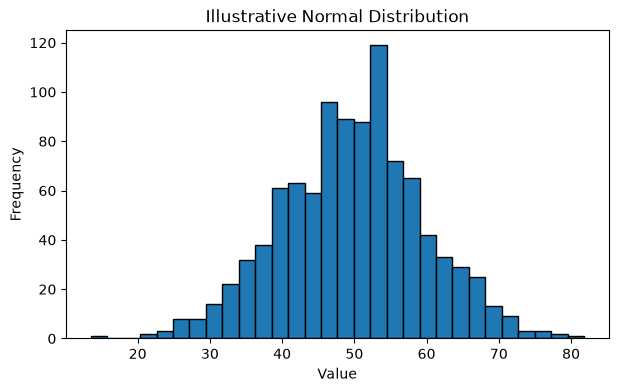

Mean: 49.71
Median: 50.06
Standard deviation: 9.89


In [2]:
rng = np.random.default_rng(42)
normal_data = rng.normal(loc=50, scale=10, size=1000)  # mean 50, standard deviation 10

plt.figure(figsize=(7, 4))
plt.hist(normal_data, bins=30, edgecolor="black")
plt.title("Illustrative Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

print("Mean:", round(normal_data.mean(), 2))
print("Median:", round(np.median(normal_data), 2))
print("Standard deviation:", round(normal_data.std(), 2))

## 2. Uniform Distribution

**Definition:** Values across a specified interval have approximately equal probability.

**Simple example:** A fair random integer from 1 to 6 is discrete uniform; a random decimal between 0 and 1 is continuous uniform.

**Real-world example:** A simulation may generate random arrival times uniformly within a short time window when that assumption is appropriate.

**Business example:** A test system may randomly select a time within a defined testing interval.

**AI/ML use case:** Uniform random values are often used to initialize parameters or sample values in simulations.

**Why it matters:** Uniform data has no single central peak. Check whether the flat pattern is expected or caused by how the data was collected.

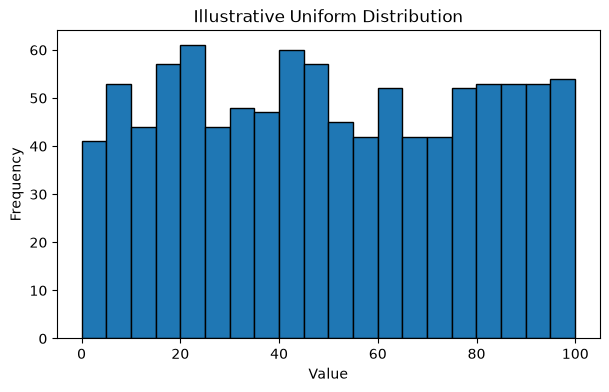

Minimum: 0.05
Maximum: 99.94
Mean: 50.34


In [3]:
uniform_data = rng.uniform(low=0, high=100, size=1000)

plt.figure(figsize=(7, 4))
plt.hist(uniform_data, bins=20, edgecolor="black")
plt.title("Illustrative Uniform Distribution"
         )
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

print("Minimum:", round(uniform_data.min(), 2))
print("Maximum:", round(uniform_data.max(), 2))
print("Mean:", round(uniform_data.mean(), 2))

## 3. Skewness

**Definition:** Skewness describes the asymmetry of a distribution.
- Near zero: approximately symmetric.
- Positive: longer tail toward larger values (right-skewed).
- Negative: longer tail toward smaller values (left-skewed).

**Simple example:** Most people may spend small amounts, while a few spend very large amounts, creating positive skew.

**Real-world example:** House prices often have a right tail because a small number of homes are extremely expensive.

**Business example:** Customer order values may be right-skewed because most orders are modest and a few are very large.

**AI/ML use case:** Strong skew can affect models sensitive to feature scale or linear relationships. A log transform may help for positive values, but check the data and model needs first.

**Why it matters:** The mean can be pulled toward the long tail, so compare mean and median and inspect the plot.

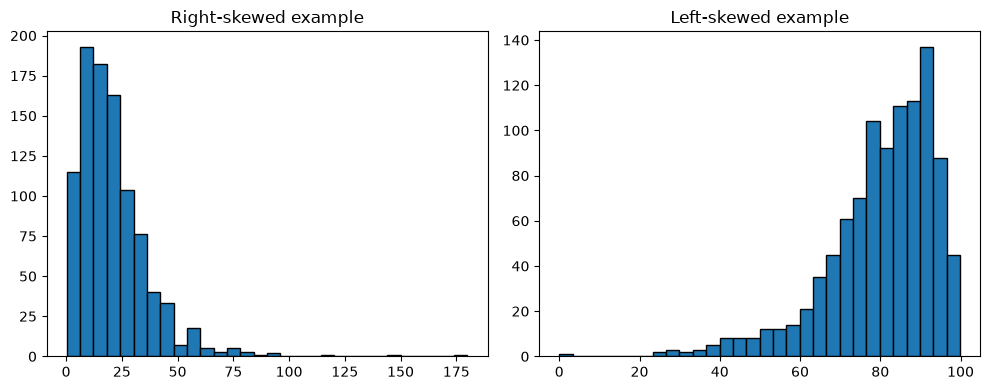

Right-skewed: mean = 21.08 | median = 17.88 | skew = 2.74
Left-skewed:  mean = 80.22 | median = 83.1 | skew = -1.4


In [4]:
right_skewed = np.concatenate([rng.gamma(shape=2, scale=10, size=950), [120, 150, 180]])
left_skewed = 100 - rng.gamma(shape=2, scale=10, size=1000)
left_skewed = np.clip(left_skewed, 0, None)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(right_skewed, bins=30, edgecolor="black")
axes[0].set_title("Right-skewed example")
axes[1].hist(left_skewed, bins=30, edgecolor="black")
axes[1].set_title("Left-skewed example")
plt.tight_layout()
plt.show()

print("Right-skewed: mean =", round(np.mean(right_skewed), 2),
      "| median =", round(np.median(right_skewed), 2),
      "| skew =", round(pd.Series(right_skewed).skew(), 2))
print("Left-skewed:  mean =", round(np.mean(left_skewed), 2),
      "| median =", round(np.median(left_skewed), 2),
      "| skew =", round(pd.Series(left_skewed).skew(), 2))

## 4. Kurtosis

**Definition:** Kurtosis describes tail heaviness and the tendency to produce extreme values relative to a normal distribution. Pandas reports **excess kurtosis**, where a normal distribution is near 0.

**Simple example:** A dataset with many ordinary values and a few extreme values may have high kurtosis.

**Real-world example:** Daily financial returns can have heavy tails, meaning extreme changes happen more often than a normal model predicts.

**Business example:** A small number of unusually large refunds can make refund amounts heavy-tailed.

**AI/ML use case:** Kurtosis can flag features with extreme observations that deserve investigation.

**Why it matters:** High kurtosis can warn that rare extremes may influence averages, estimates, and models. Kurtosis alone does not explain the cause or direction of outliers.

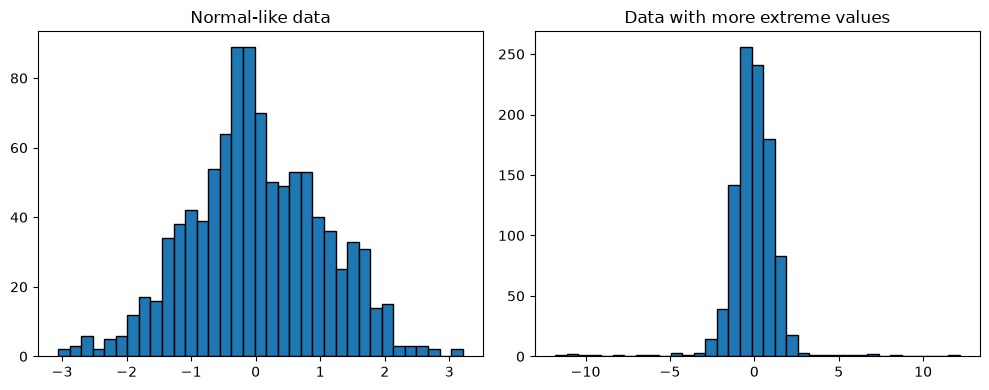

Normal-like excess kurtosis: -0.07
Heavy-tail excess kurtosis: 20.87


In [5]:
ordinary = rng.normal(0, 1, 1000)
heavy_tail = np.concatenate([rng.normal(0, 1, 970), rng.normal(0, 8, 30)])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(ordinary, bins=35, edgecolor="black")
axes[0].set_title("Normal-like data")
axes[1].hist(heavy_tail, bins=35, edgecolor="black")
axes[1].set_title("Data with more extreme values")
plt.tight_layout()
plt.show()

print("Normal-like excess kurtosis:", round(pd.Series(ordinary).kurt(), 2))
print("Heavy-tail excess kurtosis:", round(pd.Series(heavy_tail).kurt(), 2))

## 5. Symmetric Distribution

**Definition:** The left and right sides of a distribution are roughly mirror images. For a perfectly symmetric distribution, mean and median are equal.

**Simple example:** Values such as `1, 2, 3, 4, 5` are symmetric around 3.

**Real-world example:** Some measurement errors around a target may be roughly symmetric.

**Business example:** Differences from a production target may be balanced above and below the target.

**AI/ML use case:** Symmetry helps interpret residuals and select useful summaries, though symmetry is not a universal model requirement.

**Why it matters:** Mean and standard deviation can be useful summaries when the distribution is reasonably symmetric and not dominated by outliers.

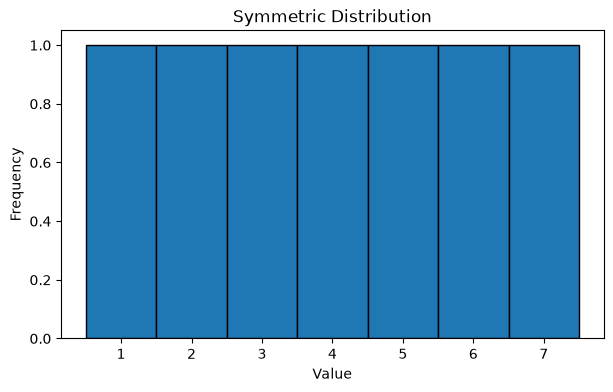

Mean: 4.0 | Median: 4.0


In [6]:
symmetric_data = np.array([1, 2, 3, 4, 5, 6, 7])
plt.figure(figsize=(7, 4))
plt.hist(symmetric_data, bins=np.arange(0.5, 8.5, 1), edgecolor="black")
plt.title("Symmetric Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()
print("Mean:", symmetric_data.mean(), "| Median:", np.median(symmetric_data))

## 6. Left-Skewed Distribution

**Definition:** A left-skewed (negatively skewed) distribution has a longer tail toward smaller values. Many observations are toward the higher end.

**Simple example:** An easy test may have most students scoring high, with a few low scores.

**Real-world example:** Scores on an easy assessment can be left-skewed.

**Business example:** A very well-rated service may receive mostly high ratings, with a few low ratings.

**AI/ML use case:** Inspect left-skewed features before scaling or transforming them; a transformation is not always necessary.

**Why it matters:** Low extreme values can pull the mean downward. Report the median and inspect the lower tail as well.

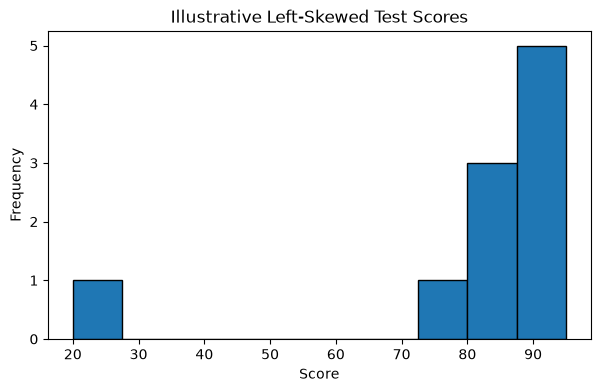

Mean: 81.1
Median: 87.5
Skewness: -2.84


In [17]:
test_scores = np.array([78, 82, 85, 87, 88, 90, 92, 94, 95, 20])
plt.figure(figsize=(7, 4))
plt.hist(test_scores, bins=10, edgecolor="black")
plt.title("Illustrative Left-Skewed Test Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()
print("Mean:", round(test_scores.mean(), 2))
print("Median:", round(np.median(test_scores), 2))
print("Skewness:", round(pd.Series(test_scores).skew(), 2))

## 7. Right-Skewed Distribution

**Definition:** A right-skewed (positively skewed) distribution has a longer tail toward larger values. Many observations are relatively small, with a few very large ones.

**Simple example:** `10, 12, 13, 15, 100` is right-skewed.

**Real-world example:** Personal income and house prices are often right-skewed.

**Business example:** Sales per customer may have a few very high-value customers.

**AI/ML use case:** For positive, strongly skewed features, a log transform may help some models; handle zeros and negatives appropriately and compare model performance.

**Why it matters:** Large values can pull the mean upward and dominate some analyses.

In [ ]:
sales = np.array([10, 12, 13, 15, 16, 18, 20, 22, 25, 120])
plt.figure(figsize=(7, 4))
plt.hist(sales, bins=8, edgecolor="black")
plt.title("Illustrative Right-Skewed Sales")
plt.xlabel("Sales units")
plt.ylabel("Frequency")
plt.show()
print("Mean:", round(sales.mean(), 2))
print("Median:", round(np.median(sales), 2))
print("Skewness:", round(pd.Series(sales).skew(), 2))

## 8. Analyze the shape, center, spread, skewness, and outliers

**Shape:** Look at a histogram and decide whether the data is symmetric, skewed, uniform, bell-shaped, or multi-peaked.

**Center:** Mean is the arithmetic average; median is the middle value. The median is more resistant to extreme values.

**Spread:** Range, interquartile range (IQR), and standard deviation describe variation in different ways.

**Skewness:** Pandas `.skew()` estimates asymmetry. Treat it as a clue, not a strict pass/fail rule.

**Outliers:** The IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. A flagged point is not automatically an error.

Shape of data: inspect histogram
Mean: 41.4
Median: 36.5
Range: 60
Standard deviation: 17.44
Q1: 34.25 | Q3: 39.5 | IQR: 5.25
Skewness: 2.92
Kurtosis (excess): 8.89
IQR outlier bounds: 26.375 to 47.375
Potential outliers: [90]


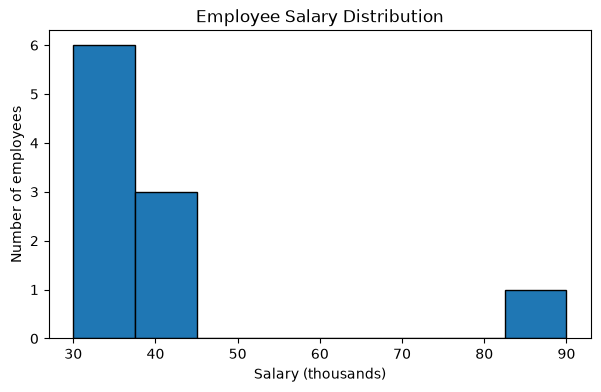

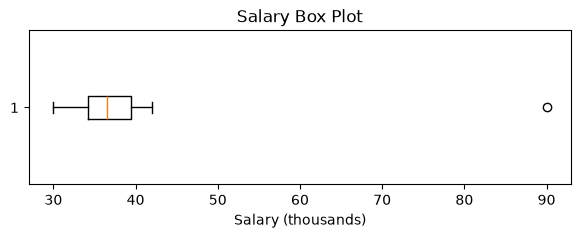

In [15]:
feature = df["salary_k"]
q1 = feature.quantile(0.25)
q3 = feature.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = feature[(feature < lower_bound) | (feature > upper_bound)]

print("Shape of data:", "inspect histogram")
print("Mean:", round(feature.mean(), 2))
print("Median:", round(feature.median(), 2))
print("Range:", int(feature.max() - feature.min()))
print("Standard deviation:", round(feature.std(), 2))
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Skewness:", round(feature.skew(), 2))
print("Kurtosis (excess):", round(feature.kurt(), 2))
print("IQR outlier bounds:", lower_bound, "to", upper_bound)
print("Potential outliers:", outliers.tolist())

plt.figure(figsize=(7, 4))
plt.hist(feature, bins=8, edgecolor="black")
plt.title("Employee Salary Distribution")
plt.xlabel("Salary (thousands)")
plt.ylabel("Number of employees")
plt.show()

plt.figure(figsize=(7, 2))
plt.boxplot(feature, orientation='horizontal')
plt.title("Salary Box Plot")
plt.xlabel("Salary (thousands)")
plt.show()

## 9. Practical interpretation example

The salary value of 90 may be flagged as unusual compared with the other values. Do not delete it automatically: it could be a real senior employee's salary, a data-entry error, or a different employee group.

A good analyst should:
1. Check the source and units.
2. Compare the value with domain knowledge.
3. Decide whether to correct, keep, cap, transform, or analyze separately.
4. Document the decision.

## Mini practice
1. Which center measure is more resistant to outliers: mean or median?
2. What does positive skewness usually indicate?
3. What does IQR measure?
4. Does a flagged outlier always mean the data is wrong?
5. Why should you plot a feature before transforming it?

In [16]:
# Optional answers: run this cell after trying the questions yourself.
answers = {
    1: "Median.",
    2: "A longer tail toward larger values.",
    3: "The spread of the middle 50% of values (Q3 - Q1).",
    4: "No. It may be a valid observation that needs investigation.",
    5: "To understand shape, identify data issues, and choose an appropriate method."
}
answers

{1: 'Median.',
 2: 'A longer tail toward larger values.',
 3: 'The spread of the middle 50% of values (Q3 - Q1).',
 4: 'No. It may be a valid observation that needs investigation.',
 5: 'To understand shape, identify data issues, and choose an appropriate method.'}